# Data Pre-processing
## Goals

The goal of this project is to identify posts that discuss pharmaceutical products and see if there is a sentiment association with some products. 

To identify posts that doscuss pharmaceutical products, a dictionary of medications with the 15 most popular medications (according to Chat) included in the dictionary.


Question to answer: "Can pretrained neural networks identify sentiment towards pharmaceutical products in Reddit mental health discussions, and does sentiment differ between medications?"

Then use DistilBERT (distilbert-base-uncased-finetuned-sst-2-english), which is a pre-trained neuaral network, and fine tune it to the Reddit Mental Health data set to get the sentiment label.

https://arxiv.org/html/2501.00241v1
https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english
https://github.com/yliJeffrey/Sentiment_Analysis_Pipeline
https://unnc.globalimpact.cn/en/publications/sentiment-analysis-using-distilbert/
https://ieeexplore.ieee.org/document/10420272

In [27]:
%pip install datasets pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [28]:
from datasets import load_dataset
ds = load_dataset("solomonk/reddit_mental_health_posts")

Repo card metadata block was not found. Setting CardData to empty.


In [29]:
df = ds["train"].to_pandas()
print(df.shape)

(151288, 10)


In [30]:
# Missing values
print(df.isnull().sum())

author             0
body            1609
created_utc        0
id                 0
num_comments       0
score              0
subreddit          0
title              0
upvote_ratio       0
url                0
dtype: int64


In [31]:
#Dropped null values in the text
df = df.dropna(subset=['body'])

In [32]:
df.head()

,author,body,created_utc,id,num_comments,score,subreddit,title,upvote_ratio,url
0,HotConversation1273,A few months ago I was accepted into this full...,2021-12-22T18:32:56.000Z,rmbjwb,1,1,ADHD,I get extremely anxious if I’m not working 24/7,1.0,https://www.reddit.com/r/ADHD/comments/rmbjwb/...
1,snorefestt,"Hey guys, I was curious if anyone else has the...",2021-12-22T18:24:25.000Z,rmbd1y,3,5,ADHD,"I can't will myself to clean my own house, but...",1.0,https://www.reddit.com/r/ADHD/comments/rmbd1y/...
2,etyf12,\n\ni have 6 exams in the next 2 weeks one of...,2021-12-22T18:22:52.000Z,rmbbvu,1,2,ADHD,i need some help,1.0,https://www.reddit.com/r/ADHD/comments/rmbbvu/...
3,GetHairOrDieTryin,Is there anyone out there that is struggling w...,2021-12-22T18:20:35.000Z,rmba1t,3,2,ADHD,Anyone up for a chat?,1.0,https://www.reddit.com/r/ADHD/comments/rmba1t/...
4,ZeroTransPat,"Whenever I get hungry, I never eat because I d...",2021-12-22T18:18:47.000Z,rmb8lm,2,1,ADHD,Figuring out what to eat sucks,1.0,https://www.reddit.com/r/ADHD/comments/rmb8lm/...


In [33]:
#Chat created a dictionary of the 15 most common medications runtime was 53.78 seconds on 100,000 data points. 
#Initially asked for a dictionary of as many medications and run time was way too large.
import re

medications = {
    # Antidepressants - SSRIs
    "sertraline": ["sertraline", "zoloft", "lustral"],
    "fluoxetine": ["fluoxetine", "prozac"],
    "escitalopram": ["escitalopram", "lexapro", "cipralex"],
    "citalopram": ["citalopram", "celexa", "cipramil"],
    "paroxetine": ["paroxetine", "paxil", "seroxat"],

    # Other antidepressants
    "venlafaxine": ["venlafaxine", "effexor", "efexor"],
    "duloxetine": ["duloxetine", "cymbalta"],
    "bupropion": ["bupropion", "wellbutrin"],
    "mirtazapine": ["mirtazapine", "remeron", "zispin"],

    # ADHD medications
    "methylphenidate": ["methylphenidate", "ritalin", "concerta"],
    "lisdexamfetamine": ["lisdexamfetamine", "vyvanse", "elvanse"],
    "amphetamine": ["adderall"],

    # Anti-anxiety medications
    "alprazolam": ["alprazolam", "xanax"],
    "diazepam": ["diazepam", "valium"],

    # Mood stabilisers
    "lamotrigine": ["lamotrigine", "lamictal"]
}


In [34]:
def find_medications(text):
    found = []

    for drug, names in medications.items():
        if any(
            re.search(
                rf"\b{re.escape(name)}\b",
                text,
                flags=re.IGNORECASE
            )
            for name in names
        ):
            found.append(drug)

    return found

In [35]:
df["medications"] = df["body"].apply(find_medications)

df["mentions_medication"] = (
    df["medications"].apply(lambda x: len(x) > 0)
)

print(df["mentions_medication"].value_counts())

mentions_medication
False    142765
True       6914
Name: count, dtype: int64


Out of 151288 rows 6914 mention a medication in the dictionary. Two new columns are added to the data frame, the 'medications' column contatins a list of the medications mentioned in the post, the 'mentions_medications' columns contains True/False values that tell us if a post mentions a medication.

In [36]:
df.head()

,author,body,created_utc,id,num_comments,score,subreddit,title,upvote_ratio,url,medications,mentions_medication
0,HotConversation1273,A few months ago I was accepted into this full...,2021-12-22T18:32:56.000Z,rmbjwb,1,1,ADHD,I get extremely anxious if I’m not working 24/7,1.0,https://www.reddit.com/r/ADHD/comments/rmbjwb/...,[],False
1,snorefestt,"Hey guys, I was curious if anyone else has the...",2021-12-22T18:24:25.000Z,rmbd1y,3,5,ADHD,"I can't will myself to clean my own house, but...",1.0,https://www.reddit.com/r/ADHD/comments/rmbd1y/...,[],False
2,etyf12,\n\ni have 6 exams in the next 2 weeks one of...,2021-12-22T18:22:52.000Z,rmbbvu,1,2,ADHD,i need some help,1.0,https://www.reddit.com/r/ADHD/comments/rmbbvu/...,[],False
3,GetHairOrDieTryin,Is there anyone out there that is struggling w...,2021-12-22T18:20:35.000Z,rmba1t,3,2,ADHD,Anyone up for a chat?,1.0,https://www.reddit.com/r/ADHD/comments/rmba1t/...,[],False
4,ZeroTransPat,"Whenever I get hungry, I never eat because I d...",2021-12-22T18:18:47.000Z,rmb8lm,2,1,ADHD,Figuring out what to eat sucks,1.0,https://www.reddit.com/r/ADHD/comments/rmb8lm/...,[],False


In [37]:
df_medications = df[
    df["mentions_medication"] == True
].copy()

The df_medications data frame only contains posts that mention a mediation with a subset shown below.

In [38]:
df_medications.to_csv("reddit_medications.csv", index=False)

In [39]:
import pandas as pd

df_medications = pd.read_csv("reddit_medications.csv")

In [40]:
df_medications.head()

,author,body,created_utc,id,num_comments,score,subreddit,title,upvote_ratio,url,medications,mentions_medication
0,Used_Inspection2618,I’m on 20 mg of Lexapro and 50 mg Vyvanse and ...,2021-12-22T18:15:52.000Z,rmb6f2,4,1,ADHD,Drinking while on meds?,1.0,https://www.reddit.com/r/ADHD/comments/rmb6f2/...,"['escitalopram', 'lisdexamfetamine']",True
1,Field-cave1519,"I'm a newly diagnosed 42 yr old female, who st...",2021-12-22T18:11:07.000Z,rmb2i8,1,1,ADHD,Does everyone get the euphoria feeling when th...,1.0,https://www.reddit.com/r/ADHD/comments/rmb2i8/...,['amphetamine'],True
2,Away_Entertainment29,TL;DR - rough time titrating on concerta for t...,2021-12-22T18:09:50.000Z,rmb1ib,1,1,ADHD,Xaggatin: zoned out and angry,1.0,https://www.reddit.com/r/ADHD/comments/rmb1ib/...,['methylphenidate'],True
3,-seeker_,"Hello everyone,\n\nMy life is falling apart an...",2021-12-22T18:04:04.000Z,rmawvm,0,2,ADHD,"Need your support, advice & help please! Life ...",1.0,https://www.reddit.com/r/ADHD/comments/rmawvm/...,"['methylphenidate', 'lisdexamfetamine']",True
4,shirayuku_desu,"Hi, I’m college student who has a boyfriend wi...",2021-12-22T17:47:23.000Z,rmajk8,3,1,ADHD,Studying tips,1.0,https://www.reddit.com/r/ADHD/comments/rmajk8/...,['amphetamine'],True


medications
amphetamine         2278
methylphenidate     1797
lisdexamfetamine    1609
sertraline           789
bupropion            593
fluoxetine           564
escitalopram         481
alprazolam           191
venlafaxine          177
paroxetine           149
citalopram           121
lamotrigine          120
mirtazapine           78
duloxetine            75
diazepam              60
Name: count, dtype: int64


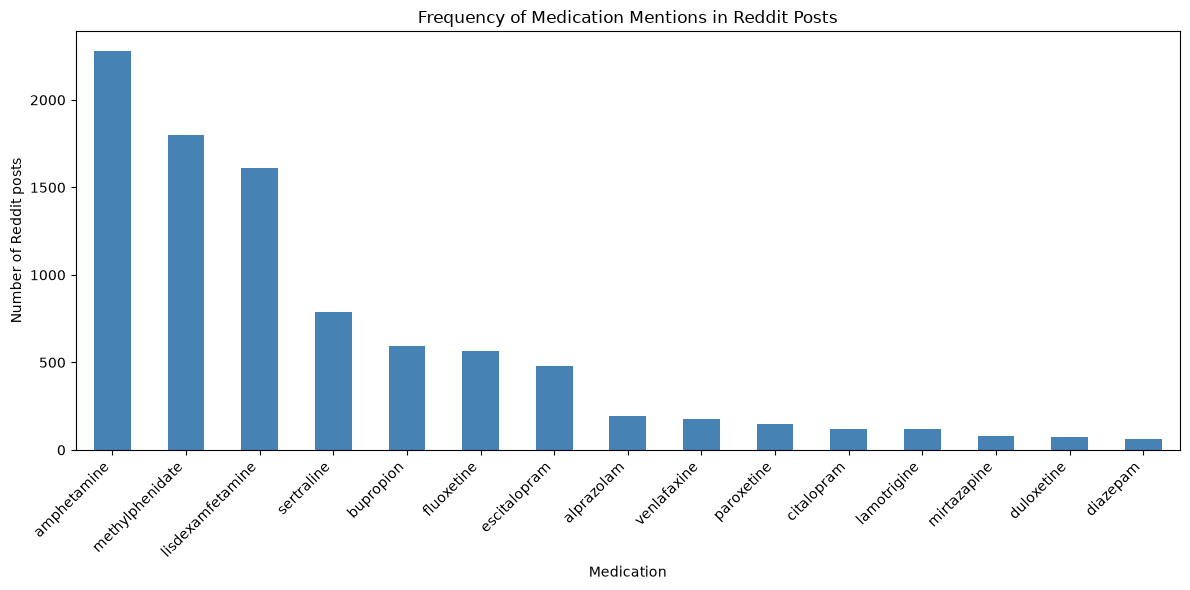

In [14]:
import matplotlib.pyplot as plt

# Count how many posts mention each medication
medication_counts = (
    df["medications"]
    .explode()
    .value_counts()
)

# Print the results
print(medication_counts)

# Plot a bar chart
plt.figure(figsize=(12, 6))

medication_counts.plot(kind="bar", color="steelblue")

plt.xlabel("Medication")
plt.ylabel("Number of Reddit posts")
plt.title("Frequency of Medication Mentions in Reddit Posts")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Want to now prepare the data to use the DistilBERT Neural network. 

In [26]:
%pip install transformers torch

Note: you may need to restart the kernel to use updated packages.


## LDA
What themes occur in Reddit posts mentioning mental-health medications, and how does the prevalence of those themes vary by medication?

LDA uses word counts, so we will use scikit-learn's CountVectorizer. I recommend removing the medication names from the text used to train LDA, while retaining your original medications column. Otherwise, the model may discover topics that simply distinguish Zoloft from Prozac, rather than themes such as sleep, dosage or withdrawal.

In [41]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Use the medication-related posts identified in your notebook.
lda_df = df_medications.copy().reset_index(drop=True)
lda_df["post_id"] = np.arange(len(lda_df))

# Get all generic and brand names from your existing dictionary.
drug_names = set(medications.keys())

for names in medications.values():
    drug_names.update(names)

drug_pattern = re.compile(
    r"\b(?:" + "|".join(
        re.escape(name)
        for name in sorted(drug_names, key=len, reverse=True)
    ) + r")\b",
    flags=re.IGNORECASE
)

def prepare_lda_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = drug_pattern.sub(" ", text)
    return text

lda_df["lda_text"] = lda_df["body"].apply(prepare_lda_text)

This leaves the original post unchanged in body, so you can return to it when interpreting a topic.

In [42]:
vectorizer = CountVectorizer(
    stop_words="english",
    min_df=5,
    max_df=0.90,
    max_features=10000
)

X = vectorizer.fit_transform(lda_df["lda_text"])

# Remove posts with no words remaining in the vocabulary.
keep = np.asarray(X.sum(axis=1)).ravel() > 0

X = X[keep]
lda_df = lda_df.loc[keep].reset_index(drop=True)

print("Posts used:", X.shape[0])
print("Vocabulary size:", X.shape[1])

Posts used: 6914
Vocabulary size: 7345


In [44]:
n_topics = 6

lda = LatentDirichletAllocation(
    n_components=n_topics,
    learning_method="online",
    batch_size=256,
    max_iter=10,
    random_state=42
)

topic_probabilities = lda.fit_transform(X)

print(topic_probabilities.shape)

(6914, 6)


In [45]:
words = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_words = words[top_indices]

    print(f"Topic {i + 1}: {', '.join(top_words)}")

Topic 1: ocd, thoughts, intrusive, ve, generic, effects, tried, compulsions, brand, ssri, anxiety, help
Topic 2: just, like, don, feel, ve, life, time, know, things, really, want, adhd
Topic 3: heart, rate, blood, pressure, attack, high, panic, sexual, anxiety, breathing, chest, normal
Topic 4: like, just, feel, day, ve, taking, meds, really, started, don, time, medication
Topic 5: episode, got, day, close, like, things, happened, wanted, wife, room, scared, ended
Topic 6: adhd, medication, doctor, psychiatrist, told, just, diagnosed, meds, ve, said, prescribed, got


In [46]:
topic_cols = [f"topic_{i + 1}" for i in range(n_topics)]

lda_df[topic_cols] = topic_probabilities

lda_df["dominant_topic"] = (
    np.argmax(topic_probabilities, axis=1) + 1
)

lda_df["dominant_probability"] = (
    np.max(topic_probabilities, axis=1)
)

lda_df[
    ["post_id", "medications", "dominant_topic",
     "dominant_probability"] + topic_cols
].head()

,post_id,medications,dominant_topic,dominant_probability,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6
0,0,"['escitalopram', 'lisdexamfetamine']",4,0.958109,0.008359,0.008363,0.008410,0.958109,0.008383,0.008377
1,1,['amphetamine'],4,0.763988,0.001598,0.229655,0.001585,0.763988,0.001582,0.001592
2,2,['methylphenidate'],4,0.638398,0.000910,0.222497,0.000905,0.638398,0.000909,0.136381
3,3,"['methylphenidate', 'lisdexamfetamine']",2,0.729644,0.038017,0.729644,0.000227,0.014627,0.000227,0.217258
4,4,['amphetamine'],2,0.484729,0.002190,0.484729,0.052148,0.456561,0.002177,0.002196


In [47]:
topic_number = 1

examples = lda_df.nlargest(5, f"topic_{topic_number}")

for _, post in examples.iterrows():
    print("Medications:", post["medications"])
    print("Topic probability:", round(post[f"topic_{topic_number}"], 3))
    print(post["body"][:500])
    print("-" * 60)

Medications: ['lisdexamfetamine']
Topic probability: 0.98
Hi all,

Recently moved to California and might be switching to a Kaiser health plan. I have an out of state Vyvanse prescription. How bad is it going to be? I know a lot of stories on here are negative about Kaiser. I have an option for a different plan but it would cost about $2500 more a year in just monthly premium alone. Kind of nervous after reading a lot of stories. Any first hand accounts? Hoping to make the decision soon.


Thanks all,I don’t know why there are so many hoops for somethi
------------------------------------------------------------
Medications: ['lisdexamfetamine']
Topic probability: 0.98
Hi all,

Recently moved to California and might be switching to a Kaiser health plan. I have an out of state Vyvanse prescription. How bad is it going to be? I know a lot of stories on here are negative about Kaiser. I have an option for a different plan but it would cost about $2500 more a year in just monthly premium a

In [48]:
med_topic_df = lda_df[
    ["post_id", "medications"] + topic_cols
].explode("medications")

topic_by_medication = (
    med_topic_df
    .groupby("medications")[topic_cols]
    .mean()
)

post_counts = (
    med_topic_df
    .groupby("medications")["post_id"]
    .nunique()
    .rename("n_posts")
)

summary = (
    post_counts.to_frame()
    .join(topic_by_medication)
    .sort_values("n_posts", ascending=False)
)

summary.round(3)

,n_posts,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6
medications,,,,,,,
['amphetamine'],1505,0.033,0.313,0.017,0.466,0.014,0.157
['methylphenidate'],1151,0.027,0.286,0.020,0.520,0.015,0.132
['lisdexamfetamine'],906,0.026,0.260,0.028,0.534,0.014,0.136
['sertraline'],487,0.125,0.457,0.020,0.270,0.024,0.105
['fluoxetine'],347,0.129,0.432,0.018,0.302,0.021,0.097
...,...,...,...,...,...,...,...
"['sertraline', 'fluoxetine', 'venlafaxine', 'mirtazapine']",1,0.000,0.472,0.060,0.155,0.054,0.258
"['bupropion', 'diazepam']",1,0.001,0.728,0.053,0.215,0.001,0.001
"['venlafaxine', 'methylphenidate', 'lisdexamfetamine', 'amphetamine']",1,0.003,0.003,0.003,0.953,0.033,0.003


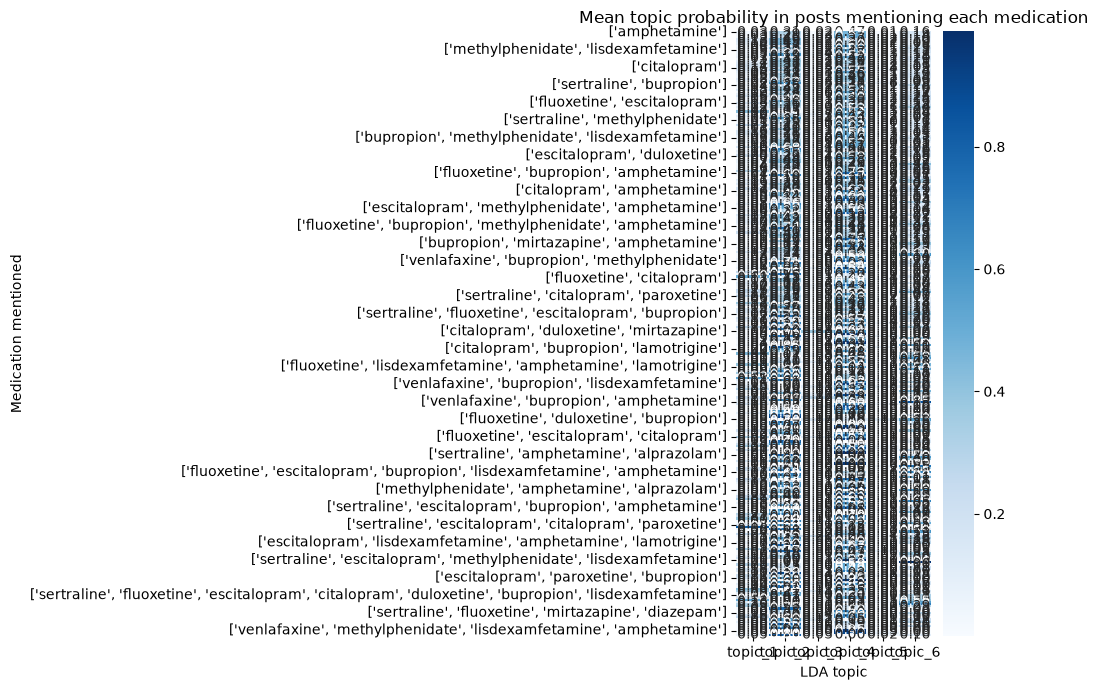

In [49]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    summary[topic_cols],
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.xlabel("LDA topic")
plt.ylabel("Medication mentioned")
plt.title("Mean topic probability in posts mentioning each medication")
plt.tight_layout()
plt.show()

In [50]:
single_med = lda_df[
    lda_df["medications"].str.len() == 1
].explode("medications")

single_med_summary = (
    single_med.groupby("medications")[topic_cols].mean()
)

single_med_summary.round(3)

,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6
medications,,,,,,
